# 16 · Revised complete ML pipeline

[Guide](../README.md) | [Previous](15_Final_Frozen_Solution.ipynb)

## 1. What problem are we solving?

Reproduce the revised recipe: select a cutoff on training rows, check validation, then refit and predict the competition test rows.

## 2. Why does it matter?

A reproducible pipeline separates model selection, validation, and unknown test predictions.

## 3. Key concepts

| Term | Simple meaning |
|---|---|
| Training-selected cutoff | A decision boundary chosen from training out-of-fold predictions, not unknown test answers. |
| Out-of-fold prediction | A prediction for a training row made by a model fitted without that row. |
| Validation vs test | Validation has known labels for checking; competition test does not expose its answers. |
| Expected-rate experiment | Rank test probabilities to enforce an assumed goal fraction. The assumption is not measured from the unlabeled file or established by the validation score. |
| Pipeline notation | `clone` copies unfitted settings; `step__setting` changes one pipeline setting. Earlier steps stay fixed during a comparison. |

## 4. Intuitive example

A penalty has predicted goal probability 0.48. At cutoff 0.50 we predict a miss; at 0.47 we predict a goal. Lowering the cutoff finds more goals but can also create false goals. Choose the best balance using training predictions, then check the fixed choice on validation.

## 5. Selection and prediction plan

| Stage | What we do | Why |
|---|---|---|
| Select the cutoff | Try 0.01 to 0.99 on training out-of-fold predictions | Choose the highest training F1 without validation/test answers |
| Check validation | Apply the chosen cutoff without changing it | Check the fixed recipe on separate rows |
| Refit and export | Train on all labeled rows; keep that cutoff | Predict every competition-test row |
| Optional expected-rate example | Label the upper half of test probabilities as goals | Illustrate a separate 50% assumption, not a training-selected improvement |

The model settings stay fixed. Only the cutoff is searched here.

## 6. What we retained from previous notebooks

| Phase | Choice |
|---|---|
| Missing values | Keep rows; fill numbers with the median and categories with the mode |
| Scaling and encoding | Robust scaling and one-hot encoding |
| Features | 20 candidate features from Notebook 05 |
| Selection | Drop suspected decoys, then L1 selection |
| Outliers | Add an indicator; do not delete rows just because they look unusual |
| Balancing and PCA | No resampling; no PCA |
| Model | One CatBoost model: 200 trees, depth 6, learning rate 0.1 |
| Normal decision cutoff | Recompute below from training-only predictions; the saved earlier run selected 0.47 |

**Difference from Notebook 15:** that original recipe drops incomplete training rows and uses 0.50. This revised recipe keeps/imputes them. An earlier training-only check favored keeping rows (CV F1 0.9473 vs 0.9461 at cutoff 0.50). The code below now reproduces cutoff selection; the best selection score is not independent validation.

## 7. Setup

**Reusable setup — run this cell, then skip to the lesson.** You do not need to study all these lines now: they load the data and rebuild earlier steps so this notebook works on its own. Revisit the earlier lessons for explanations.

Change `DATA_DIR` for your runtime. The cell starts collapsed where the editor supports it; GitHub may show it expanded. `X` contains inputs; `y` contains known answers. Learned preparation stays inside training folds.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.precision", 3)

# Change this one folder on Kaggle or Colab (see the guide).
DATA_DIR = "../data"
train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")
print("Train:", train.shape, "Test:", test.shape)

# Split train.csv: 80% for training, 20% for a separate validation check.
training_data, validation_data = train_test_split(
    train, test_size=0.20, stratify=train["is_scored"], random_state=2026
)
training_data = training_data.reset_index(drop=True)

# IDs identify rows; they do not describe how a penalty was taken.
id_columns = ["id", "kicker_id", "keeper_id", "match_id"]
X = training_data.drop(columns=id_columns + ["is_scored"])
y = training_data["is_scored"]

from sklearn.base import clone
from sklearn.compose import make_column_selector
from sklearn.preprocessing import FunctionTransformer, RobustScaler
from sklearn.feature_selection import SelectFromModel
from imblearn.pipeline import Pipeline
from catboost import CatBoostClassifier

def drop_suspected_decoys(data):
    return data.drop(columns=["jersey_color", "referee_strictness"], errors="ignore")

def add_relative_features(data):
    data = data.copy()
    data["skill_gap"] = data["player_last5_scored_percent"] - data["goalkeeper_last5_saved_percent"]
    data["foot_advantage"] = data["strong_foot_usage"] - data["weak_foot_usage"]
    data["form_ratio"] = (data["player_last5_scored_percent"] + 1) / (data["goalkeeper_last5_saved_percent"] + 1)
    data["form_interaction"] = data["player_last5_scored_percent"] * data["goalkeeper_last5_saved_percent"] / 100
    data["player_form_squared"] = (data["player_last5_scored_percent"] / 100) ** 2
    data["keeper_form_squared"] = (data["goalkeeper_last5_saved_percent"] / 100) ** 2
    return data

def add_pressure_features(data):
    data = data.copy()
    data["late_close_game"] = ((data["minute_taken"] >= 75) & (data["current_score_diff"].abs() <= 1)).astype(int)
    gap = data["player_last5_scored_percent"] - data["goalkeeper_last5_saved_percent"]
    data["skill_under_pressure"] = gap * data["late_close_game"]
    data["after_90_minutes"] = (data["minute_taken"] > 90).astype(int)
    data["trailing"] = (data["current_score_diff"] < 0).astype(int)
    data["tied_game"] = (data["current_score_diff"] == 0).astype(int)
    data["minute_score_interaction"] = data["minute_taken"] * data["current_score_diff"]
    data["crowd_support"] = (data["home_or_away"] == data["crowd_behind_goal"]).astype(int)
    data["late_final"] = ((data["minute_taken"] >= 75) & (data["match_type"] == "Final")).astype(int)
    return data

def add_environment_features(data):
    data = data.copy()
    data["poor_pitch"] = (data["pitch_condition"] == "Poor").astype(int)
    data["poor_pitch_late"] = data["poor_pitch"] * (data["minute_taken"] >= 75)
    data["humidity_weak_foot"] = data["weather_humidity"] / 100 * data["weak_foot_usage"]
    data["humidity_squared"] = (data["weather_humidity"] / 100) ** 2
    data["temperature_squared"] = data["temperature"] ** 2
    data["log_capacity"] = np.log1p(data["stadium_capacity"])
    return data

def add_features(data):
    data = add_relative_features(data)
    data = add_pressure_features(data)
    return add_environment_features(data)

def suspicious_rows(data):
    # Screening rules, not proof: unusual time, cold weather, or very large venue.
    return ((data["minute_taken"] > 120) |
            (data["temperature"] < 0) |
            (data["stadium_capacity"] > 110000))

def add_outlier_flag(data):
    data = data.copy()
    data["unusual_kick"] = suspicious_rows(data).astype(int)
    return data

numbers = Pipeline([("fill", SimpleImputer(strategy='median')), ("scale", RobustScaler())])
categories = Pipeline([
    ("fill", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocess = ColumnTransformer([
    ("numbers", numbers, make_column_selector(dtype_include="number")),
    ("categories", categories, make_column_selector(dtype_exclude="number")),
])

pipeline = Pipeline([
    ("outlier_values", FunctionTransformer(add_outlier_flag)),
    ("features", FunctionTransformer(add_features)),
    ("decoys", FunctionTransformer(drop_suspected_decoys)),
    ("prepare", preprocess),
    ("selection", SelectFromModel(LogisticRegression(penalty="l1", solver="liblinear", max_iter=1000, random_state=42))),
    ("model", CatBoostClassifier(iterations=200, depth=6, learning_rate=0.1, loss_function='Logloss', random_seed=42, thread_count=2, verbose=False, allow_writing_files=False)),
])

selected_model = clone(pipeline)

Train: (20000, 20) Test: (6000, 19)


## 8. Experiments

Complete run: **Kaggle, 16 October 2026**. Select the cutoff using training rows only, check the fixed recipe on validation, then refit on all labeled rows and export. The expected-rate example stays optional and separate.

### Select the cutoff using training rows only

Split the 16,000 training rows into three **folds** (groups). For each group, fit the whole pipeline on the other two and predict this unseen group. Combine these **out-of-fold probabilities** so each training kick has a prediction from a model that did not train on it. Filling, scaling, encoding, and selection are refitted inside each fold.

Example: a goal with probability 0.48 is missed at cutoff 0.50, but found at 0.47. Lowering the cutoff can also create extra false goals, so compare F1 across all training rows. Neither validation answers nor competition-test rows enter this search.

In [2]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import f1_score

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
training_probability = cross_val_predict(
    selected_model, X, y, cv=cv, method="predict_proba", n_jobs=1
)[:, 1]

Try cutoffs from 0.01 to 0.99. Choose the one with the highest F1 (the lower cutoff wins an exact tie). The earlier run selected **0.47**; the value below is computed, not forced.

This F1 helps select the cutoff, so it is an optimistic selection score. Use the next validation check to evaluate the fixed decision.

,cutoff,training F1
46,0.47,0.948


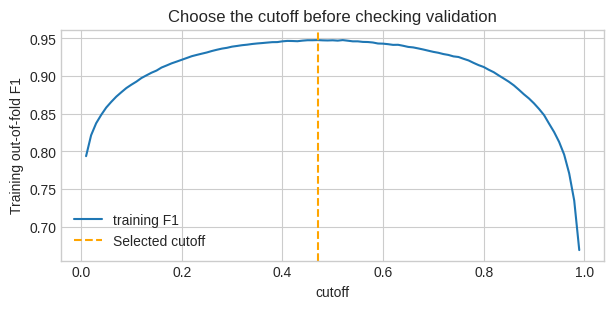

In [3]:
cutoffs = np.arange(0.01, 1.00, 0.01)
cutoff_results = pd.DataFrame({
    "cutoff": cutoffs,
    "training F1": [f1_score(y, training_probability >= cutoff) for cutoff in cutoffs],
})
best_row = cutoff_results["training F1"].idxmax()
TRAINING_CUTOFF = float(cutoff_results.loc[best_row, "cutoff"])
display(cutoff_results.loc[[best_row]].round(4))
cutoff_results.plot(x="cutoff", y="training F1", figsize=(7, 3), legend=False)
plt.axvline(TRAINING_CUTOFF, color="orange", linestyle="--", label="Selected cutoff")
plt.ylabel("Training out-of-fold F1")
plt.title("Choose the cutoff before checking validation")
plt.legend()
plt.show()

### Check the fixed recipe on validation rows

F1 balances precision (how often a predicted goal is correct) and recall (how many real goals we find).
Use the cutoff selected on training predictions; do not choose it from this validation score.

This validation split has been inspected before. Treat its score as a learning example, not a fresh independent benchmark. Performance on a different dataset may change.

,validation F1,validation accuracy,validation ROC-AUC
0,0.941,0.947,0.991


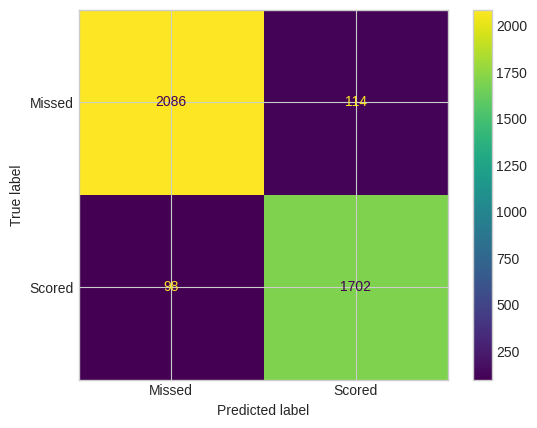

In [4]:
from sklearn.metrics import f1_score, accuracy_score, roc_auc_score, ConfusionMatrixDisplay
X_valid = validation_data.drop(columns=id_columns + ["is_scored"])
y_valid = validation_data["is_scored"]
selected_model.fit(X, y)
validation_probability = selected_model.predict_proba(X_valid)[:, 1]
validation_prediction = (validation_probability >= TRAINING_CUTOFF).astype(int)
validation_results = pd.DataFrame([[
    f1_score(y_valid, validation_prediction), accuracy_score(y_valid, validation_prediction),
    roc_auc_score(y_valid, validation_probability),
]], columns=["validation F1", "validation accuracy", "validation ROC-AUC"])
display(validation_results.round(4))
ConfusionMatrixDisplay.from_predictions(y_valid, validation_prediction, display_labels=["Missed", "Scored"])
plt.show()

### Fit the same model using the full training file

Keep and impute incomplete rows. Every competition-test row gets a probability and a prediction.

In [5]:
final_model = clone(selected_model)
X_all = train.drop(columns=id_columns + ["is_scored"])
y_all = train["is_scored"]
X_test = test.drop(columns=id_columns)
final_model.fit(X_all, y_all)
test_probability = final_model.predict_proba(X_test)[:, 1]
prediction = (test_probability >= TRAINING_CUTOFF).astype(int)
submission = pd.DataFrame({"id": test["id"], "is_scored": prediction})
assert len(submission) == len(test)
assert submission["id"].is_unique and submission["is_scored"].isin([0, 1]).all()
display(submission.head())

,id,is_scored
0,20000,1
1,20001,0
2,20002,1
3,20003,0
4,20004,1


In [6]:
from pathlib import Path
OUTPUT_DIR = "../results/pipeline_update"
Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)
submission.to_csv(f"{OUTPUT_DIR}/learning_pipeline_training_cutoff.csv", index=False)
print("Saved the normal training-selected predictions.")

Saved the normal training-selected predictions.


In [7]:
validation_results.to_csv(f"{OUTPUT_DIR}/validation_results.csv", index=False)

### Optional: what if we expect half the penalties to score?

**Assumption, not a measured fact:** about 50% of the test penalties are goals. We cannot determine the true goal rate from an unlabeled test file.

Rank the predicted probabilities and label the upper half as goals. `quantile(0.50)` finds the middle probability, which becomes the new cutoff.

This example changes only the decision rule. It does not rebalance training data or make the probabilities more accurate. The 50% assumption was not selected by training validation. Use a rule like this only when a credible, independent source supports the expected rate. Otherwise, keep the training-selected cutoff. A wrong assumption can lower F1.

In [8]:
EXPECTED_TEST_GOAL_RATE = 0.50
competition_cutoff = np.quantile(test_probability, 1 - EXPECTED_TEST_GOAL_RATE)
competition_prediction = (test_probability >= competition_cutoff).astype(int)
competition_submission = pd.DataFrame({"id": test["id"], "is_scored": competition_prediction})
competition_submission.to_csv(f"{OUTPUT_DIR}/learning_pipeline_expected50_experiment.csv", index=False)
print("Experiment cutoff:", round(competition_cutoff, 4))
print("Predicted goals:", competition_prediction.sum(), "out of", len(test))

Experiment cutoff: 0.148
Predicted goals: 3000 out of 6000


**What changed for one penalty?** A probability between the two cutoffs changes from miss to goal. We have changed the decision rule, not retrained the model or proved that the new label is correct.

In [9]:
prediction_examples = pd.DataFrame({
    "id": test["id"], "goal_probability": test_probability,
    "normal_prediction": prediction, "experiment_prediction": competition_prediction,
})
display(prediction_examples.loc[prediction != competition_prediction].head().round(3))
prediction_examples.to_csv(f"{OUTPUT_DIR}/learning_pipeline_probabilities.csv", index=False)

,id,goal_probability,normal_prediction,experiment_prediction
7,20007,0.165,0,1
19,20019,0.301,0,1
35,20035,0.422,0,1
60,20060,0.363,0,1
76,20076,0.153,0,1


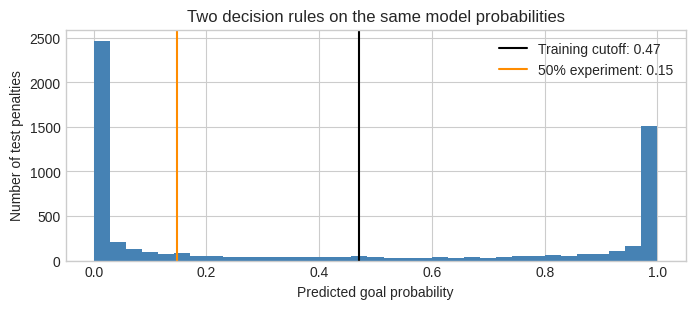

In [10]:
plt.figure(figsize=(8, 3))
plt.hist(test_probability, bins=35, color="steelblue")
plt.axvline(TRAINING_CUTOFF, color="black", label=f"Training cutoff: {TRAINING_CUTOFF:.2f}")
plt.axvline(competition_cutoff, color="darkorange", label=f"50% experiment: {competition_cutoff:.2f}")
plt.xlabel("Predicted goal probability")
plt.ylabel("Number of test penalties")
plt.title("Two decision rules on the same model probabilities")
plt.legend()
plt.show()

### Export summary

The normal file uses the training-selected cutoff. The optional file uses the assumed 50% goal rate. Keep their names separate: the assumption-based experiment is not the default ML pipeline and has no independently validated test score in this notebook.

In [11]:
export_summary = pd.DataFrame({
    "file": ["learning_pipeline_training_cutoff.csv", "learning_pipeline_expected50_experiment.csv"],
    "cutoff": [TRAINING_CUTOFF, competition_cutoff],
    "predicted_goals": [prediction.sum(), competition_prediction.sum()],
    "test_rows": [len(test), len(test)],
})
display(export_summary.round(4))
export_summary.to_csv(f"{OUTPUT_DIR}/pipeline_export_summary.csv", index=False)

,file,cutoff,predicted_goals,test_rows
0,learning_pipeline_training_cutoff.csv,0.470,2478,6000
1,learning_pipeline_expected50_experiment.csv,0.148,3000,6000


## 9. Results and decision

| Question | Answer |
|---|---|
| What did we compare? | Compare training cutoffs for the revised fixed model; separately illustrate a training-selected cutoff versus an explicitly assumed 50% goal-rate rule. |
| Which performed best? | Fixed standard recipe: validation F1 0.9414. This is not a new model comparison or a score for the 50%-rate experiment. |
| Why did we choose it? | Training-only follow-up checks favored keeping/imputing rows and cutoff 0.47; the separate validation check documents that fixed recipe. |
| What are its limitations? | The validation split has been inspected before. A presumed test goal fraction is not measurable from unlabeled inputs and is not a general replacement for training-selected thresholds. |
| What continues to the next notebook? | Export the normal cutoff-0.47 submission; keep the assumed-rate file separate and optional. No later lesson. |

The complete run reproduced cutoff **0.47** from training-only predictions (selection F1 **0.9476**). The separate validation F1 is **0.9414**; it is not a score for the assumed-rate example.

## 10. Key takeaways and next step

- Validation, refitting, and competition prediction are different steps.
- Keep assumption-based cutoff examples separate from the training-selected pipeline.

Next: review the exported predictions and document the chosen decision rule; keep experiments separate from the standard recipe.